# figure 2
smoke attribution of gpp change at each site (results from 2_smoke_regression)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
titles = {"US-Bi2": "US-Bi2 irrigated corn", "US-Ne1": "US-Ne1 irrigated maize", "US-Ne2": "US-Ne2 irrigated maize",
          "US-Ne3": "US-Ne3 rainfed maize", "US-xUN": "US-xUN mixed forest", "US-UMB": "US-UMB deciduous forest",
          "US-MMS": "US-MMS deciduous forest", "US-Ha1": "US-Ha1 deciduous forest"}
bars = pd.read_csv("results/bar_effects.csv").set_index(["site", "component"])
order = [("light", "Less total light", "#E69F00"), ("diffuse", "More diffuse light", "#56B4E9"),
         ("radiation", "Net radiation effect", "#0072B2"), ("vpd", "Change in VPD", "#009E73"),
         ("swc", "Change in soil moisture", "#CC79A7"), ("ta", "Change in temperature", "#D55E00"),
         ("total", "Total GPP response", "#999999")]
layout = [["US-Bi2", "US-xUN"], ["US-Ne1", "US-UMB"], ["US-Ne2", "US-MMS"], ["US-Ne3", "US-Ha1"]]

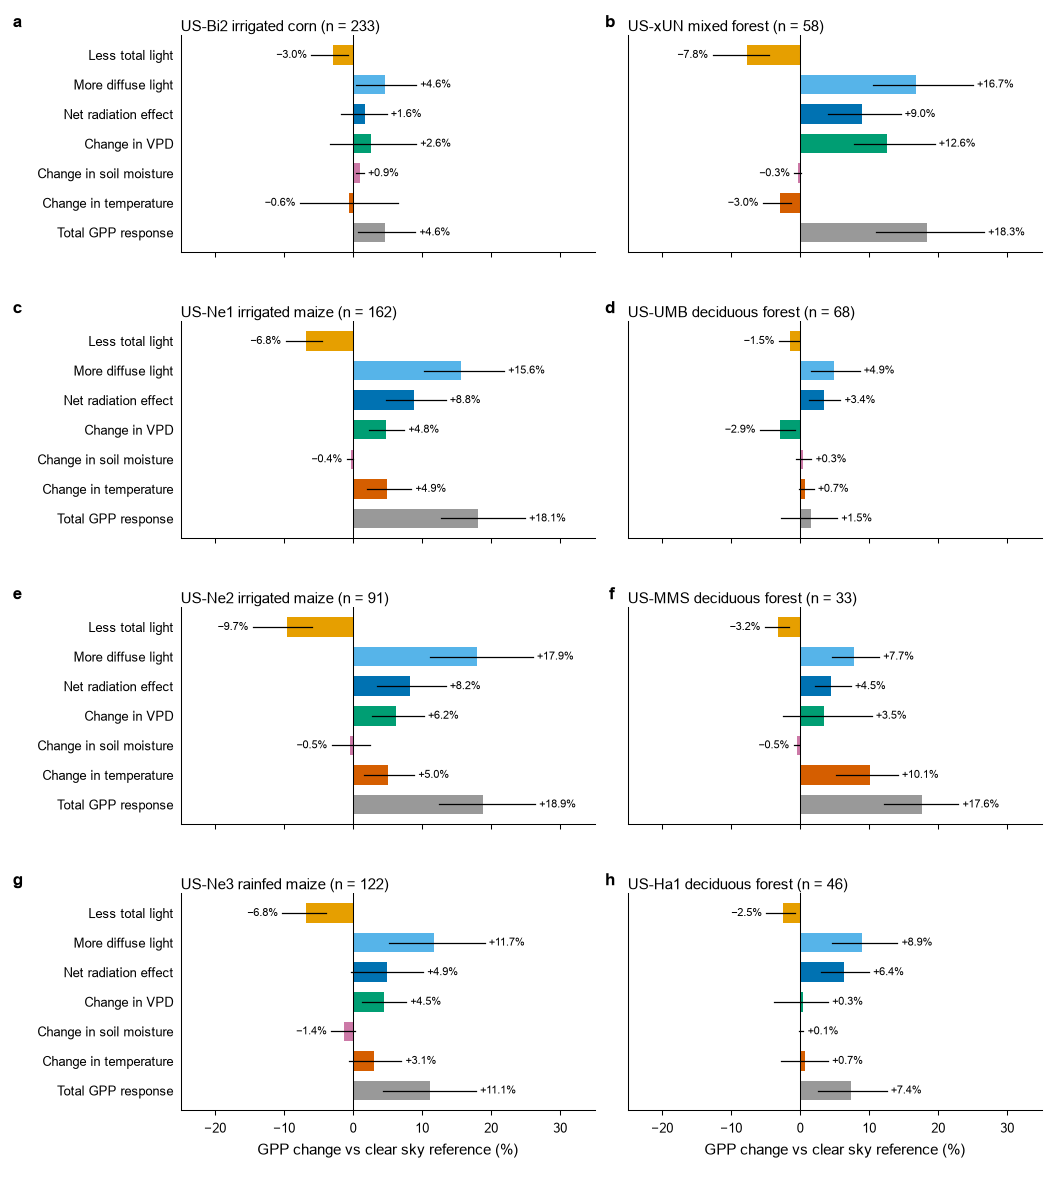

In [2]:
lo, hi = bars.lo.min(), bars.hi.max()
xlim = (5 * np.floor((lo - 7) / 5), 5 * np.ceil((hi + 7) / 5))
fig, axes = plt.subplots(4, 2, figsize=(180 * mm, 200 * mm), sharex=True)
fig.subplots_adjust(left=0.17, right=0.98, top=0.97, bottom=0.06, wspace=0.08, hspace=0.32)
ys = np.arange(len(order))[::-1]
for r, row in enumerate(layout):
    for c, site in enumerate(row):
        ax = axes[r, c]
        for y, (k, lab, col) in zip(ys, order):
            v = bars.loc[(site, k)]
            ax.barh(y, v.pct, height=0.66, color=col, lw=0)
            ax.plot([v.lo, v.hi], [y, y], color="black", lw=0.6)
            pos = v.pct >= 0
            ax.annotate(f"{v.pct:+.1f}%".replace("-", "−"), (max(v.hi, v.pct, 0) if pos else min(v.lo, v.pct), y),
                        xytext=(2 if pos else -2, 0), textcoords="offset points", va="center",
                        ha="left" if pos else "right", fontsize=5.5)
        ax.axvline(0, color="black", lw=0.5)
        ax.set_yticks(ys); ax.set_yticklabels([o[1] for o in order] if c == 0 else [])
        ax.tick_params(axis="y", length=0)
        ax.set_xlim(*xlim)
        ax.set_title(f"{titles[site]} (n = {bars.loc[(site, 'total'), 'n']})", pad=2)
        b = ax.get_position()
        fig.text(0.012 if c == 0 else b.x0 - 0.012, b.y1 + 0.004, "abcdefgh"[2 * r + c], fontsize=8,
                 fontweight="bold", ha="left" if c == 0 else "right", va="bottom")
        ax.xaxis.set_major_formatter(minus)
for ax in axes[-1]:
    ax.set_xlabel("GPP change vs clear sky reference (%)")
fig.savefig("figures/fig2_smoke_effects.png", dpi=600)